# Projet 4 : Classifiez automatiquement des informations

## Analyse exploratoire des données (EDA)

### 1 - Chargement des librairies et du fichier

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sb
import numpy as np

In [3]:
DATA_RAW = Path("../Data/Raw")

df_brut_sondage = pd.read_csv(DATA_RAW / "extrait_sondage.csv")

### 2 - Audit du dataset

dataset complet

In [4]:
df_brut_sondage

,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,code_sondage,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
0,Oui,0,0,1,1,1,2,Infra & Cloud,Y,Occasionnel,0,5
1,Non,1,3,1,2,8,1,Infra & Cloud,Y,Frequent,1,7
2,Oui,0,3,1,4,2,2,Autre,Y,Occasionnel,0,0
3,Non,0,3,1,5,3,4,Infra & Cloud,Y,Frequent,3,0
4,Non,1,3,1,7,2,1,Transformation Digitale,Y,Occasionnel,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...
1465,Non,1,3,1,2061,23,2,Transformation Digitale,Y,Frequent,0,3
1466,Non,1,5,1,2062,6,1,Transformation Digitale,Y,Occasionnel,1,7
1467,Non,1,0,1,2064,4,3,Infra & Cloud,Y,Occasionnel,0,3
1468,Non,0,3,1,2065,2,3,Transformation Digitale,Y,Frequent,0,8


Dimensions du dataset

In [4]:
df_brut_sondage.shape

(1470, 12)

Nulls, et types de colonnes

In [5]:
df_brut_sondage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 12 columns):
 #   Column                               Non-Null Count  Dtype 
---  ------                               --------------  ----- 
 0   a_quitte_l_entreprise                1470 non-null   object
 1   nombre_participation_pee             1470 non-null   int64 
 2   nb_formations_suivies                1470 non-null   int64 
 3   nombre_employee_sous_responsabilite  1470 non-null   int64 
 4   code_sondage                         1470 non-null   int64 
 5   distance_domicile_travail            1470 non-null   int64 
 6   niveau_education                     1470 non-null   int64 
 7   domaine_etude                        1470 non-null   object
 8   ayant_enfants                        1470 non-null   object
 9   frequence_deplacement                1470 non-null   object
 10  annees_depuis_la_derniere_promotion  1470 non-null   int64 
 11  annes_sous_responsable_actuel        1470 n

Min, Max

In [6]:
df_brut_sondage.describe(include='all')

,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,code_sondage,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
count,1470,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470,1470,1470,1470.000000,1470.000000
unique,2,NaN,NaN,NaN,NaN,NaN,NaN,6,1,3,NaN,NaN
top,Non,NaN,NaN,NaN,NaN,NaN,NaN,Infra & Cloud,Y,Occasionnel,NaN,NaN
freq,1233,NaN,NaN,NaN,NaN,NaN,NaN,606,1470,1043,NaN,NaN
mean,NaN,0.793878,2.799320,1.0,1024.865306,9.192517,2.912925,NaN,NaN,NaN,2.187755,4.123129
std,NaN,0.852077,1.289271,0.0,602.024335,8.106864,1.024165,NaN,NaN,NaN,3.222430,3.568136
min,NaN,0.000000,0.000000,1.0,1.000000,1.000000,1.000000,NaN,NaN,NaN,0.000000,0.000000
25%,NaN,0.000000,2.000000,1.0,491.250000,2.000000,2.000000,NaN,NaN,NaN,0.000000,2.000000
50%,NaN,1.000000,3.000000,1.0,1020.500000,7.000000,3.000000,NaN,NaN,NaN,1.000000,3.000000
75%,NaN,1.000000,3.000000,1.0,1555.750000,14.000000,4.000000,NaN,NaN,NaN,3.000000,7.000000


Doubons sur tout le dataset

In [7]:
df_brut_sondage.duplicated().value_counts()

False    1470
Name: count, dtype: int64

Doublons sur la colonne identifiante 

In [8]:
df_brut_sondage.duplicated(subset=['code_sondage']).value_counts()

False    1470
Name: count, dtype: int64

### 3 - Exploration des données

In [9]:
df_brut_sondage

,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,code_sondage,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
0,Oui,0,0,1,1,1,2,Infra & Cloud,Y,Occasionnel,0,5
1,Non,1,3,1,2,8,1,Infra & Cloud,Y,Frequent,1,7
2,Oui,0,3,1,4,2,2,Autre,Y,Occasionnel,0,0
3,Non,0,3,1,5,3,4,Infra & Cloud,Y,Frequent,3,0
4,Non,1,3,1,7,2,1,Transformation Digitale,Y,Occasionnel,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...
1465,Non,1,3,1,2061,23,2,Transformation Digitale,Y,Frequent,0,3
1466,Non,1,5,1,2062,6,1,Transformation Digitale,Y,Occasionnel,1,7
1467,Non,1,0,1,2064,4,3,Infra & Cloud,Y,Occasionnel,0,3
1468,Non,0,3,1,2065,2,3,Transformation Digitale,Y,Frequent,0,8


Proportion des personnes qui ont quitte l'entreprise 

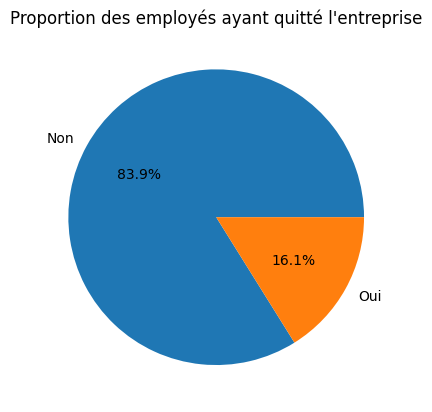

In [16]:
comptes = df_brut_sondage['a_quitte_l_entreprise'].value_counts()

plt.pie(comptes, labels=comptes.index, autopct="%1.1f%%")
plt.title("Proportion des employés ayant quitté l'entreprise")
plt.show()



Distribution du nombre de formation par employés

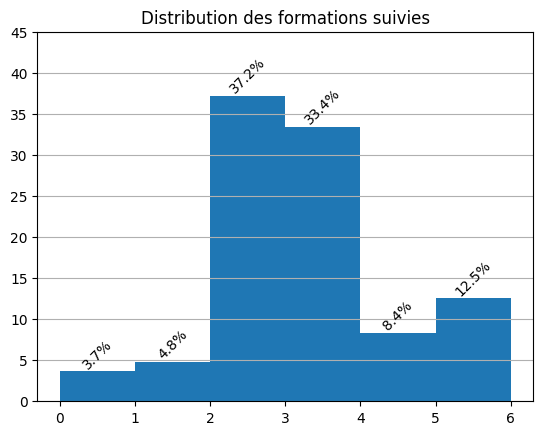

In [ ]:
poids = np.ones(len(df_brut_sondage['nb_formations_suivies'])) / len(df_brut_sondage['nb_formations_suivies']) * 100

effectifs, bornes, barres  = plt.hist(df_brut_sondage['nb_formations_suivies'], bins=6, weights=poids)
plt.title("Distribution des formations suivies")
plt.bar_label(barres,fmt="%.1f%%", rotation=45)
plt.ylim(top= 45)
plt.grid(axis='y')

Distribution de la distance Domicile-Travail

(array([503., 188., 249., 135.,  40.,  78.,  73.,  64.,  78.,  62.]),
 array([ 1. ,  3.8,  6.6,  9.4, 12.2, 15. , 17.8, 20.6, 23.4, 26.2, 29. ]),
 <BarContainer object of 10 artists>)

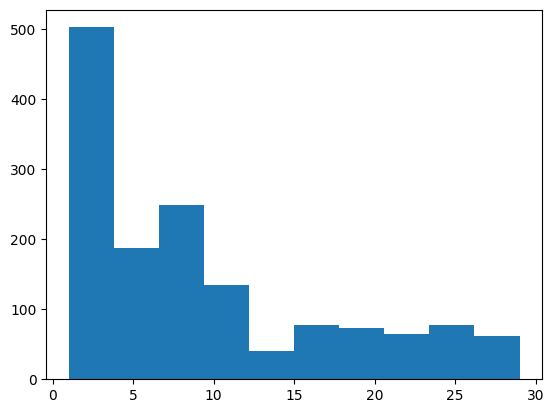

In [ ]:
plt.hist(df_brut_sondage['distance_domicile_travail'])

Proportion des domaines d'étude 

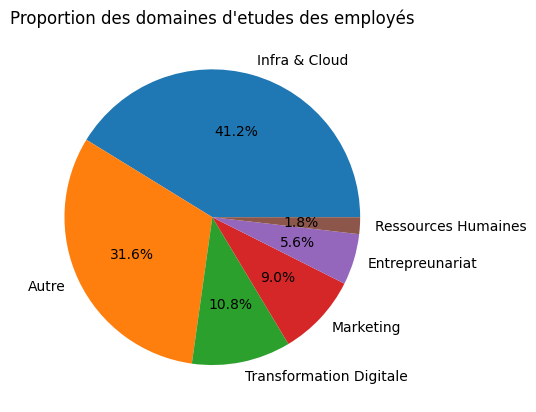

In [ ]:
plt.pie(df_brut_sondage['domaine_etude'].value_counts(),labels=df_brut_sondage['domaine_etude'].unique(), autopct="%1.1f%%")
plt.title("Proportion des domaines d'etudes des employés")
plt.show()

Proportion des employés ayant des enfants 

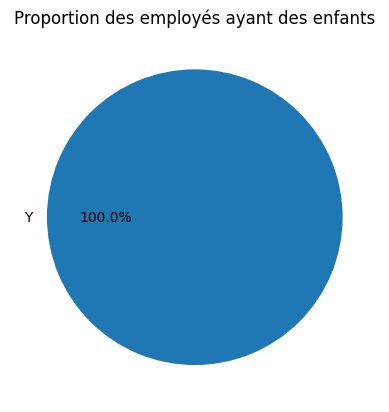

In [ ]:
plt.pie(df_brut_sondage['ayant_enfants'].value_counts(),labels=df_brut_sondage['ayant_enfants'].unique(), autopct="%1.1f%%")
plt.title("Proportion des employés ayant des enfants")
plt.show()

Proportion des employés qui font des déplacements pro

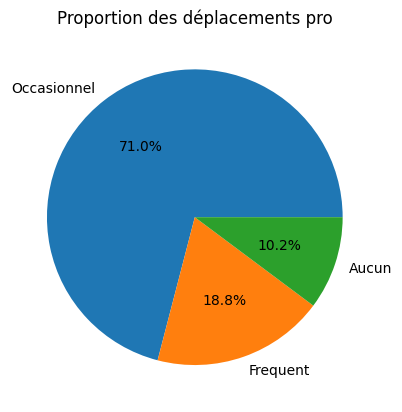

In [ ]:
plt.pie(df_brut_sondage['frequence_deplacement'].value_counts(),labels=df_brut_sondage['frequence_deplacement'].unique(), autopct="%1.1f%%")
plt.title("Proportion des déplacements pro")
plt.show()